# Do peer-relative moves actually reverse?

October 28, 2026. This is a follow-up on already examined history, **gross/pre-fee only**. [Full explanation](experiments/equity_reversal_response/README.md), [fixed specification](experiments/equity_reversal_response/specification.json), [reproducible source](experiments/equity_reversal_response.py).

**Result:** none of the overall response slopes or gross event means establishes an effect distinct from zero at 1, 5, or 20 sessions. The peer-stability differences are also unresolved. Persistent peers and predictable catch-up are different findings.

The notebook displays saved audited outputs; it does not silently rerun the experiment or select a best horizon. The script writes its specification before computing outcomes.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
candidates = [Path.cwd(), Path.cwd() / "Senior-Fall" / "TDA_Research", *Path.cwd().parents]
project = next(p for p in candidates if (p / "START_HERE.md").is_file() and (p / "equity").is_dir())
root = project / "equity"
out = root / "experiments" / "equity_reversal_response"
summary = pd.read_csv(out / "response_summary.csv")
bins = pd.read_csv(out / "binned_response.csv")
stability = pd.read_csv(out / "stability_response.csv")
specification = json.loads((out / "specification.json").read_text())
audit = json.loads((out / "independent_audit.json").read_text())
implementation = json.loads((out / "implementation_audit.json").read_text())
assert all(audit["checks"].values()) and all(implementation["checks"].values())
print("Formation dates:", implementation["dates_by_period"])
print("Horizons:", specification["horizons_sessions"], "sessions including entry")
print("Fees:", specification["fees"])
print("Uncertainty:", specification["uncertainty"])

Formation dates: {'development': 1851, 'evaluation': 689}
Horizons: [1, 5, 20] sessions including entry
Fees: excluded entirely
Uncertainty: 1000 circular moving-block date resamples; block 60 sessions; all stocks together


## Read the curve before the profit number

Each stock's signal is its one-day WLS residual divided by its **prior total daily volatility**. This is a normalized return shock, not a price-spread z-score. Future returns start at the next vendor-bar open, then end at the close of session 1, 5, or 20. The future relative-return outcome uses the same formation exposures and regression weights.

A downward response means prior relative losers catch up and prior winners give back. An upward response means continuation. A noisy curve near zero means no clear association. The point intervals resample dates with all stocks together; the bins are not independent experiments. Some individual bin intervals exclude zero, but there is no repeatable overall reversal pattern and no multiplicity-adjusted threshold discovery.

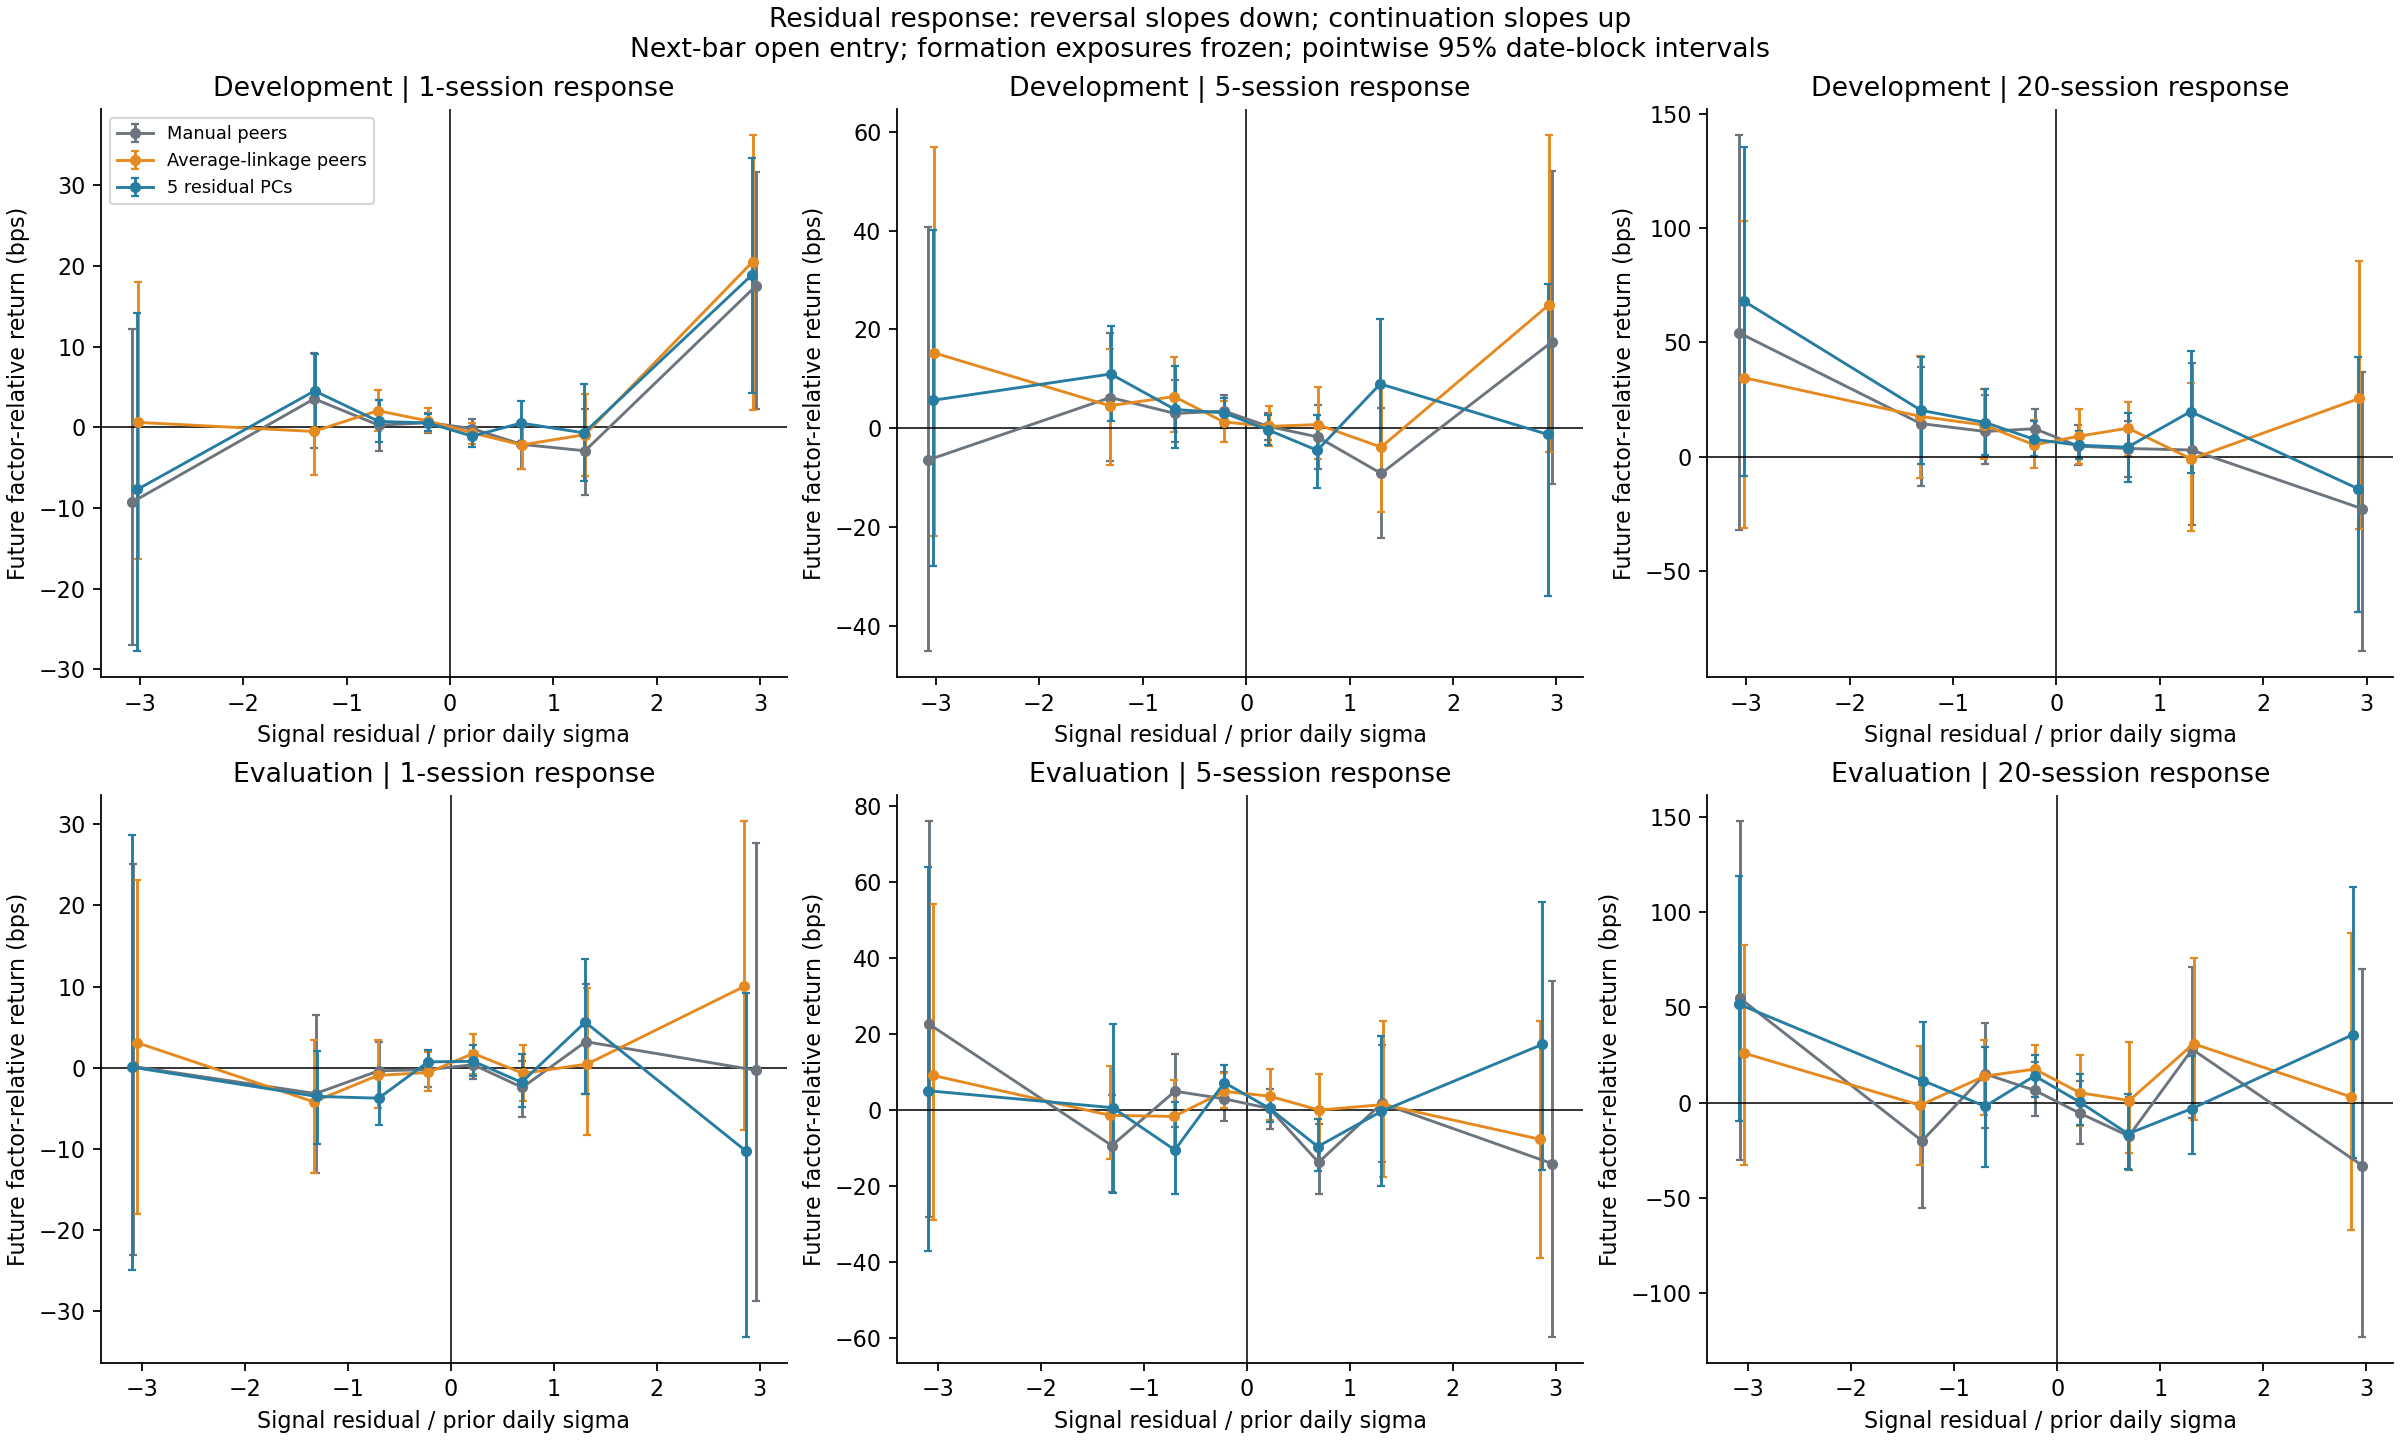

,model,horizon,bin_label,stock_events,dates_with_events,future_relative_bps,low,high
72,Manual6,1,<-2,127,110,0.162,-23.078,25.109
73,Manual6,1,-2 to -1,773,451,-3.174,-12.912,6.446
74,Manual6,1,-1 to -0.5,2374,653,-0.368,-4.135,3.134
75,Manual6,1,-0.5 to 0,7133,689,-0.231,-2.409,2.111
76,Manual6,1,0 to 0.5,6964,689,0.379,-1.362,2.061
...,...,...,...,...,...,...,...,...
139,PCA5,20,-0.5 to 0,6934,689,14.069,2.963,24.803
140,PCA5,20,0 to 0.5,6984,689,0.311,-11.622,14.868
141,PCA5,20,0.5 to 1,2444,658,-16.306,-34.886,4.479
142,PCA5,20,1 to 2,843,435,-3.110,-26.719,24.741


In [2]:
display(Image(filename=str(out / "01_residual_response_bins.png")))
display(bins.loc[bins.period.eq("evaluation"), ["model", "horizon", "bin_label", "stock_events", "dates_with_events", "future_relative_bps", "low", "high"]].round(3))

## Overall response and what the initial positions earned

All models have **seven independent initial exposure constraints**. Complete group indicators span dollar exposure; PCA uses an explicit dollar column, SPY beta, and five residual PCs. Holdings are proportional to **minus W times the signal residual**, then scaled to unit gross.

The response slope pools normalized stock/date observations through zero; **negative means reversal**. The gross return is the cumulative return of the initial unit-gross sleeves; **positive means the contrarian position earns**. Their aggregation weights differ, so pooled signs need not be opposite. Every overall interval includes zero in both periods.

Manual peers' later five-session mean and PCA's later twenty-session mean are positive estimates, not validated winners. These overlapping events are **not compounded, annualized, or presented as a funded multi-cohort trading strategy**. No capital-allocation rule for simultaneous cohorts has been specified. Initial neutrality may drift during multi-session holds.

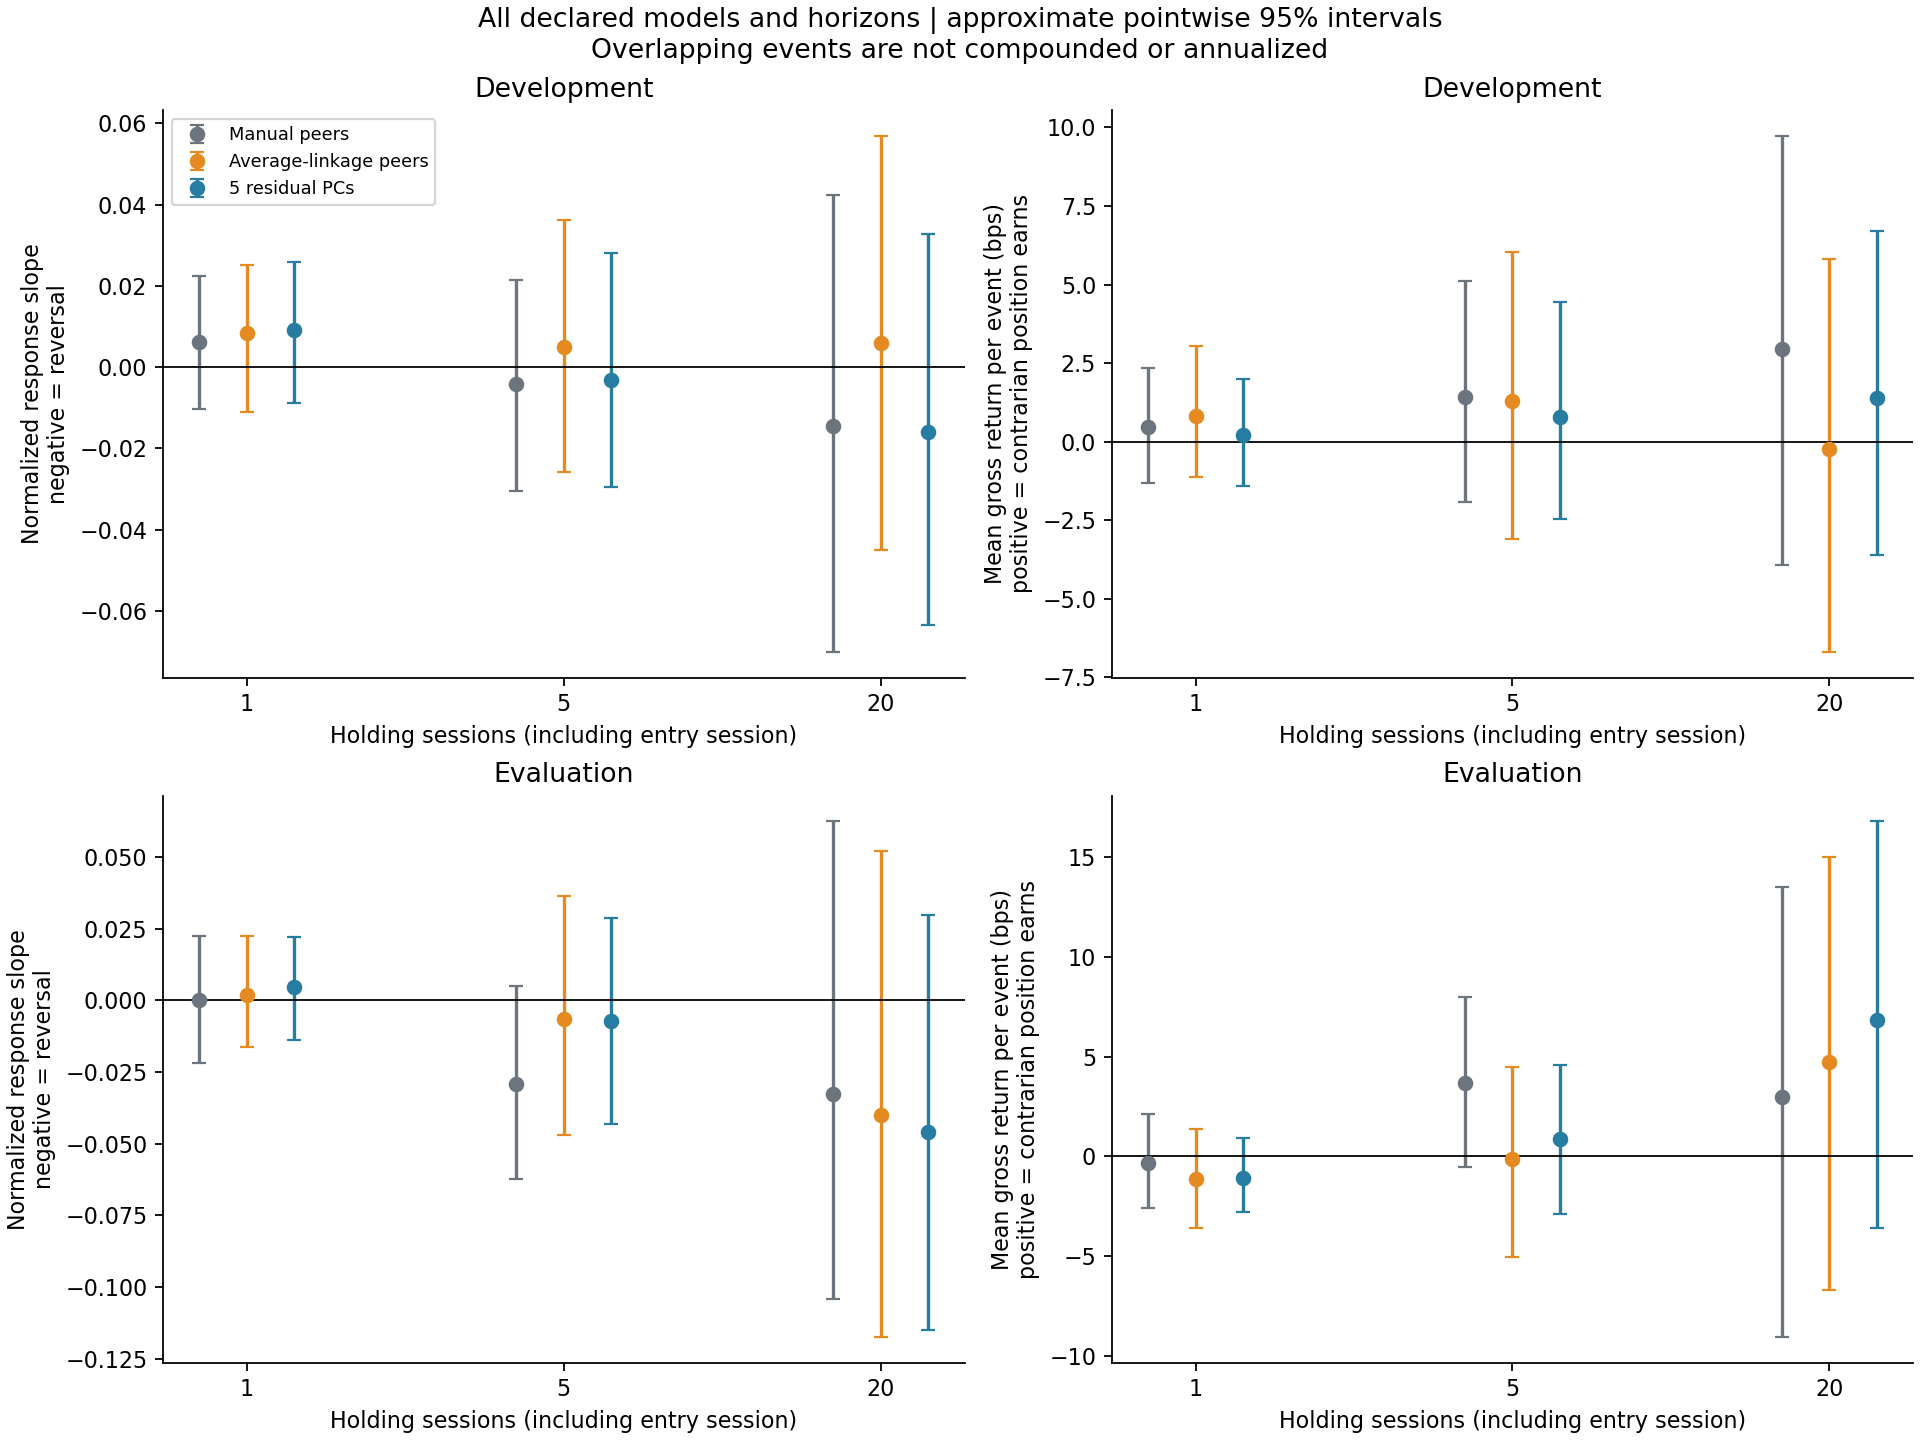

,period,model,horizon,signal_dates,stock_events,response_slope,slope_low,slope_high,mean_gross_event_bps,gross_low,gross_high
0,development,Manual6,1,1851,55530,0.0061,-0.0104,0.0225,0.4739,-1.3062,2.3579
1,development,Manual6,5,1851,55530,-0.0042,-0.0304,0.0213,1.4106,-1.9327,5.1063
2,development,Manual6,20,1851,55530,-0.0144,-0.0700,0.0424,2.9422,-3.9296,9.7243
3,development,Average6,1,1851,53588,0.0084,-0.0109,0.0251,0.8173,-1.1136,3.0374
4,development,Average6,5,1851,53588,0.0049,-0.0257,0.0362,1.2814,-3.0810,6.0294
5,development,Average6,20,1851,53588,0.0059,-0.0451,0.0568,-0.2399,-6.6845,5.8137
6,development,PCA5,1,1851,55530,0.0091,-0.0088,0.0258,0.2249,-1.3962,1.9823
7,development,PCA5,5,1851,55530,-0.0031,-0.0295,0.0281,0.7923,-2.4578,4.4418
8,development,PCA5,20,1851,55530,-0.0160,-0.0633,0.0329,1.4002,-3.6050,6.7135
9,evaluation,Manual6,1,689,20670,0.0001,-0.0218,0.0224,-0.3507,-2.5742,2.1142


In [3]:
display(Image(filename=str(out / "02_slopes_and_gross_event_returns.png")))
display(summary.round(4))
assert ((summary.slope_low < 0) & (summary.slope_high > 0)).all()
assert ((summary.gross_low < 0) & (summary.gross_high > 0)).all()

## Do more stable peers reverse more?

For average linkage only, each stock's peer set is compared across three past-only window variations: 100 sessions, 140 sessions, and a five-session-older 120-session history. The average Jaccard overlap measures shared peers divided by the union of peers. **High stability is at least 0.75**, fixed before computing outcomes.

Manual groups never change by design and PCA has no discrete membership, so neither supplies this comparison. Exact zero signals, including constrained singleton stocks, do not enter the descriptive subsets.

Negative **high-minus-lower** slopes would support stronger reversal among stable assignments. Every such interval includes zero in both periods. This is a subset association, not an exposure-neutral filtered strategy or a causal effect of stability. It tests window sensitivity, not all forms of stability.

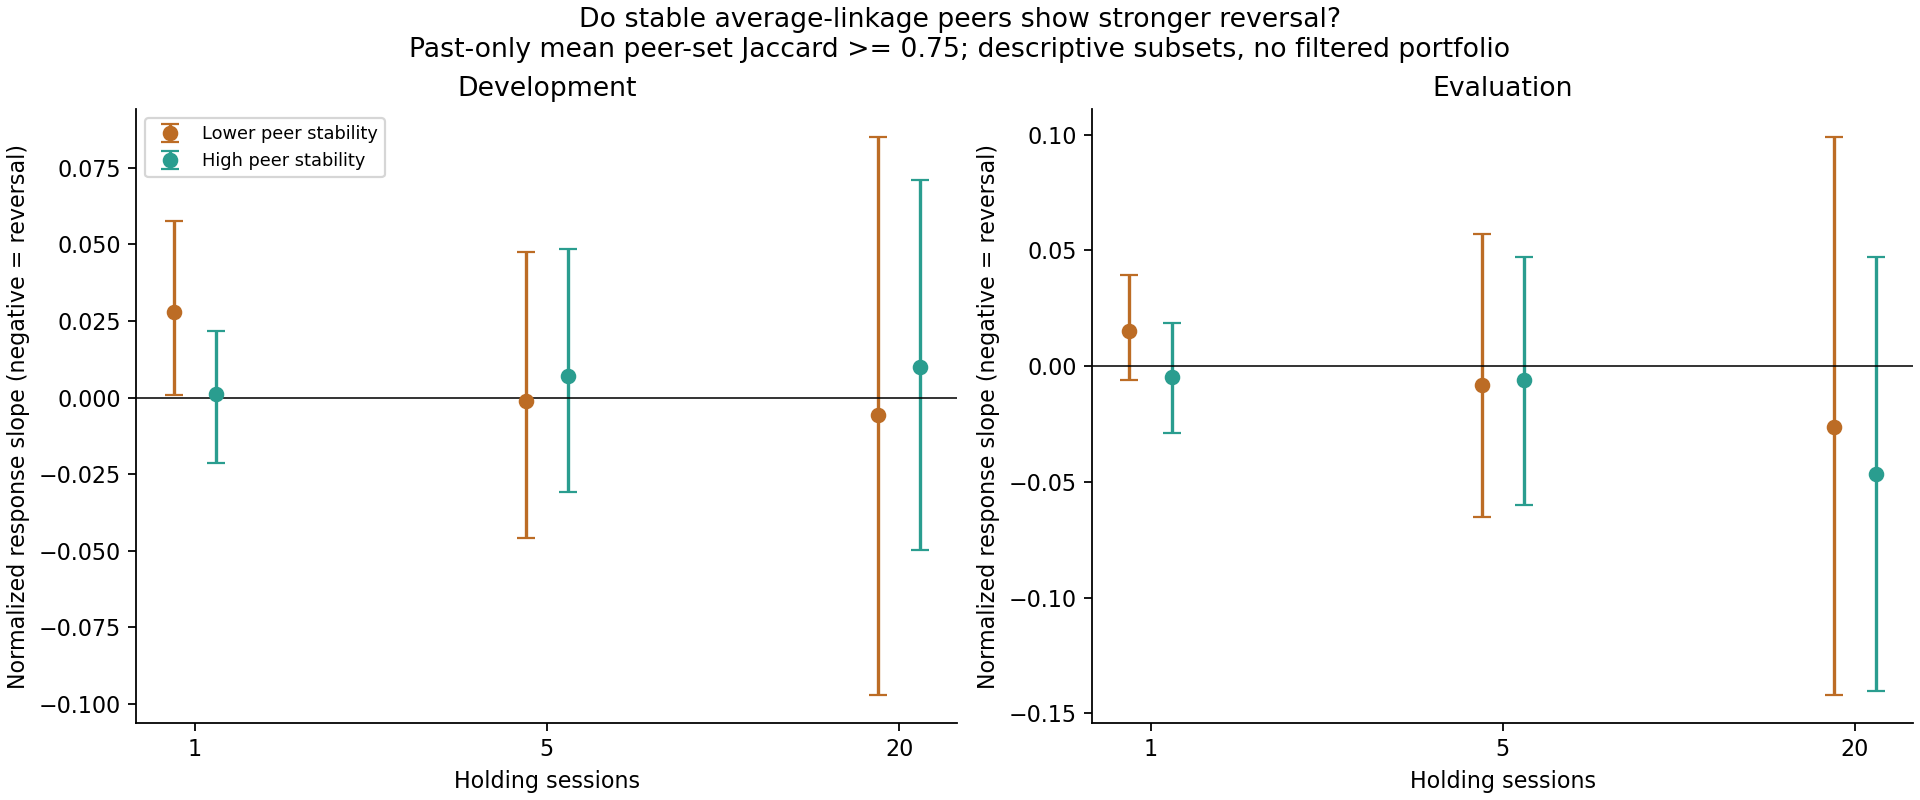

,period,horizon,stability_group,response_slope,low,high,stock_events,signal_dates
0,development,1,lower,0.0280,0.0008,0.0578,12862,1577
1,development,1,high,0.0012,-0.0215,0.0217,40726,1845
2,development,1,high_minus_lower,-0.0268,-0.0601,0.0038,53588,1851
3,development,5,lower,-0.0010,-0.0460,0.0475,12862,1577
4,development,5,high,0.0071,-0.0307,0.0486,40726,1845
5,development,5,high_minus_lower,0.0081,-0.0557,0.0744,53588,1851
6,development,20,lower,-0.0056,-0.0972,0.0850,12862,1577
7,development,20,high,0.0101,-0.0496,0.0709,40726,1845
8,development,20,high_minus_lower,0.0157,-0.0933,0.1276,53588,1851
9,evaluation,1,lower,0.0154,-0.0058,0.0393,5945,630


In [4]:
display(Image(filename=str(out / "03_stability_and_reversal.png")))
display(stability.round(4))
differences = stability.loc[stability.stability_group.eq("high_minus_lower")]
assert ((differences.low < 0) & (differences.high > 0)).all()

## Price conventions and evidence limits

Every horizon uses all-adjusted vendor opens/closes for a consistent cross-date split/dividend return proxy. This is not a verified corporate-action cash ledger or verified regular-session auction execution. The raw one-session control reproduces the earlier pilot; the maximum adjusted-minus-raw one-event difference is about **1.08 bps**. The original pilot is preserved.

All horizons share formation dates with complete twenty-session outcomes; the last incomplete dates and targets spanning the 2024 boundary are omitted. This gives 1,851 development and 689 later dates, rather than the earlier one-session sample. Circular 60-date bootstrap blocks accommodate overlap approximately; intervals are pointwise and do not cover all research choices. The 2026-selected survivor basket and already examined history remain important limitations.

Future WLS projection is only a measurement of the outcome. No future return is used to form positions. The frozen formation exposures make portfolio returns equal to their factor-relative attribution algebraically; they do not guarantee true risk neutrality throughout the hold.

In [5]:
print("Implementation checks:")
for name, passed in implementation["checks"].items():
    print(name, passed)
print("Independent reconstruction errors:", audit["max_absolute_independent_reconstruction_errors"])
print("Maximum initial scaled exposure error:", implementation["max_initial_scaled_exposure_error"])
print("Maximum raw one-session pilot reproduction error:", implementation["max_raw_one_session_pilot_error"])
print("Maximum adjusted-minus-raw one-session event return, bps:", implementation["max_adjusted_minus_raw_one_session_event_return"] * 1e4)
assert all(audit["checks"].values())

Implementation checks:
synthetic_reversal_negative_slope_positive_gross True
synthetic_continuation_positive_slope_negative_gross True
future_projection_preserves_neutral_portfolio_pnl True
peer_stability_label_invariant True
horizon_includes_entry_session True
formation_inputs_precede_signal_and_entry True
same_dates_for_all_models_and_horizons True
full_twenty_session_targets_do_not_cross_split True
seven_independent_exposures_every_formation True
interval_resampling_keeps_all_stocks_together True
original_sources_and_data_unchanged True
raw_one_session_reproduces_prior_pilot True
Independent reconstruction errors: {'holding': 2.1788126858268697e-15, 'signal': 1.0269562977782698e-15, 'future': 9.974659986866641e-17, 'future_residual': 3.972516759986888e-15, 'stability': 2.220446049250313e-16}
Maximum initial scaled exposure error: 3.595507842806293e-14
Maximum raw one-session pilot reproduction error: 9.996344030316351e-17
Maximum adjusted-minus-raw one-session event return, bps: 1.0

## What this changes

We have observed persistent peer structure, but have not established that relative return shocks subsequently reverse. Longer holding intervals have not demonstrated a simple timing fix. Stable memberships have not established a better reversal response. The estimates leave room for modest effects; they do not identify crowding, company information, or another economic explanation.

Archive this bounded baseline instead of selecting a favorable horizon, signal bin, or stability threshold from the same history. A larger-universe study can test structural generalization under a declared eligibility and correlation-estimation design. A controlled BTC delay-embedding study would develop a different TDA construction. Neither requires forcing the current strategy to be profitable.

Reproduce from the equity directory with `python experiments/equity_reversal_response.py`, then `python experiments/audit_equity_reversal_response.py`. No new download or orders are involved.